# 03_7. Stress tests / Стресс-тесты

**EN.** The models were trained on 2013–2015 and calibrated on 2016–2017. A stress test asks how they behave when the world changes. Task: Y1. Evaluation only — no training or recalibration on these periods (protocol 11):

1. **COVID** (t 2019-03 … 2021-12): with and without loans in forbearance at t (in 2020–2021 part of the delinquency is administrative: payments were paused by law, not missed). COVID-19 declarations are not used by the disaster rule here.
2. **Crisis 2007–2009** (t 2007-03 … 2010-12, vintages 2006–2008): pre-crisis underwriting, falling house prices.
3. **Rising rates 2022+** (t 2022-03 … 2025-03).
4. **Vintage split**: CatBoost with the main hyperparameters trained on vintages 2014–2017 and evaluated on vintage 2018, dates ≤ 2019-02 — do the results hold for loans of a new origination year?
5. **COVID, "selected + unemployment"**: unemployment was excluded in stage 2 because its sign flipped between years; does it help when the labour market is the shock?
6. **Sign of `occupancy_status`**: investors were safer in 2013–2015 and riskier in 2007–2009; what does the model's SHAP say in each stress period?

Metrics as in 03_6; 95 % CIs by cluster bootstrap with B = 200 (samples of up to 11 M rows, protocol 11).

**RU.** Модели обучены на 2013–2015 гг. и откалиброваны на 2016–2017 гг. Стресс-тест отвечает на вопрос, как они ведут себя, когда мир меняется. Задача — Y1. Только оценка — без обучения и перекалибровки на этих периодах (протокол, п. 11):

1. **COVID** (t 2019-03 … 2021-12): с кредитами в forbearance на дату t и без них (в 2020–2021 гг. часть просрочки административная: платежи приостановлены по закону, а не пропущены). Декларации COVID-19 правило бедствий здесь не использует.
2. **Кризис 2007–2009** (t 2007-03 … 2010-12, поколения 2006–2008): докризисный андеррайтинг, падение цен на жильё.
3. **Рост ставок 2022+** (t 2022-03 … 2025-03).
4. **Разбиение по поколениям**: CatBoost с основными гиперпараметрами обучен на поколениях 2014–2017 и оценён на поколении 2018, даты ≤ 2019-02 — держатся ли результаты для кредитов нового года выдачи?
5. **COVID, «отобранные + безработица»**: безработица исключена на этапе 2, потому что её знак менялся по годам; помогает ли она, когда шок приходит через рынок труда?
6. **Знак `occupancy_status`**: инвесторы были безопаснее в 2013–2015 гг. и рискованнее в 2007–2009 гг.; что показывает SHAP модели в каждом стресс-периоде?

Метрики — как в 03_6; 95 %-е интервалы — кластерный bootstrap с B = 200 (выборки до 11 млн строк, протокол, п. 11).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import pickle
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from catboost import CatBoostClassifier
from xai_ews.config import data_config, feature_config
from xai_ews.evaluation.compare import metrics_table, pairwise
from xai_ews.evaluation.el import alert_threshold, assign_lgd
from xai_ews.evaluation.metrics import auc, calibration_slope_intercept, ks
from xai_ews.models import catboost_model as cb
from xai_ews.models import registry
from xai_ews.models.calibration import Platt
from xai_ews.data.panel import scan_panel
from xai_ews.models.data import load_eval, load_vintage_train, split_filter, to_model_frame
from xai_ews.paths import MODELS_DIR, PREDICTIONS_DIR, MODELING_DIR

OUT = MODELING_DIR / "stress"
OUT.mkdir(parents=True, exist_ok=True)
SEED, B = 20261025, 200
DCFG, SEL = data_config(), feature_config()["selected"]
FEATS, CATS = SEL["features"], SEL["categorical"]
def loan_codes(d):
    # integer loan codes for the cluster bootstrap (13 M strings would not fit)
    return d["loan_identifier"].rank("dense").to_numpy()

UNEMP = ["unemployment_rel_us", "unemployment_chg_12m_rel_us"]
TASKS = ("y1",)
MAIN = {"y1": ["b0_y1", "m1_y1", "m2_y1"]}
SCENARIOS = ["covid", "gfc", "rates"]

**EN.** For every period: all rows of the Y1 population (disaster rule applied), Platt-calibrated PD from validation, metrics with CIs; for COVID also without forbearance rows. M1 logits are saved for stage 4 (does the hybrid's gain survive the stress?).

**RU.** Для каждого периода: все строки популяции Y1 (с правилом бедствий), PD после калибровки Платта с validation, метрики с интервалами; для COVID — ещё и без строк в forbearance. Логиты M1 сохраняются для этапа 4 (сохранится ли выигрыш гибрида в стрессе?).

In [2]:
results = []
for sc in SCENARIOS:
    for task in TASKS:
        # one observation month at a time: the 13 M-row COVID sample does not fit into 8 GB at once
        df = registry.score_by_month(sc, task, MAIN[task], FEATS, CATS,
                                     keep=["loan_identifier", "m", task, "upb", "mtm_ltv", "property_state", "forbearance_now"])
        df.select("loan_identifier", "m", task, pl.col(f"z_m1_{task}").alias("logit")).write_parquet(
            PREDICTIONS_DIR / f"m1_{task}_stress_{sc}.parquet")
        lgd = assign_lgd(df, DCFG).to_numpy()
        loans = loan_codes(df)
        variants = {"all": np.ones(df.height, bool)}
        if sc == "covid":
            variants["without forbearance"] = ~df["forbearance_now"].fill_null(False).to_numpy()
        for v, mask in variants.items():
            y = df[task].to_numpy()[mask]
            t = metrics_table(y, {n: df[f"pd_{n}"].to_numpy()[mask] for n in MAIN[task]}, loans[mask],
                              lgd[mask], df["upb"].to_numpy()[mask], threshold=alert_threshold(), b=B, seed=SEED)
            results.append(t.assign(scenario=sc, variant=v, task=task))
        print(sc, task, df.height, flush=True)
        del df, lgd, loans; gc.collect()
stress = pd.concat(results).reset_index()
stress.to_csv(OUT / "stress_metrics.csv", index=False)
stress.set_index(["scenario", "variant", "task", "model"])[["n", "events", "event_rate", "mean_pd", "auc", "auc_lo", "auc_hi",
                                                           "ks", "pr_auc", "brier", "cal_slope", "cal_intercept", "alert_share", "alert_precision",
                                                           "alert_recall", "el_share_alert"]]

covid y1 10971749


gfc y1 1276794


rates y1 8947268


n  events  event_rate  mean_pd    auc  auc_lo  auc_hi     ks  pr_auc  brier  cal_slope  cal_intercept  alert_share  alert_precision  alert_recall  el_share_alert
scenario variant             task model                                                                                                                                                                          
covid    all                 y1   b0_y1  10971749  162828      0.0148   0.0020 0.7374  0.7353  0.7391 0.3554  0.0393 0.0147     0.5849         2.0466       0.0376           0.0566        0.1436          0.1258
                                  m1_y1  10971749  162828      0.0148   0.0023 0.7336  0.7317  0.7356 0.3502  0.0398 0.0147     0.5715         1.9262       0.0449           0.0553        0.1676          0.1635
                                  m2_y1  10971749  162828      0.0148   0.0022 0.7403  0.7384  0.7421 0.3562  0.0426 0.0147     0.5908         1.9729       0.0416           0.0608        0.1706          0.1699
         without forbearance y1   b0_y1  10943731  158701      0.0145   0.0020 0.7375  0.7354  0.7396 0.3558  0.0385 0.0144     0.5854         2.0251       0.0374           0.0556        0.1435          0.1258
                                  m1_y1  10943731  158701      0.0145   0.0023 0.7334  0.7312  0.7354 0.3501  0.0388 0.0144     0.5712         1.9052       0.0447           0.0541        0.1667          0.1627
                                  m2_y1  10943731  158701      0.0145   0.0022 0.7404  0.7384  0.7424 0.3562  0.0417 0.0144     0.5911         1.9519       0.0414           0.0596        0.1700          0.1694
gfc      all                 y1   b0_y1   1276794   33725      0.0264   0.0054 0.7309  0.7271  0.7351 0.3469  0.0622 0.0259     0.7194         1.6369       0.1813           0.0627        0.4303          0.4033
                                  m1_y1   1276794   33725      0.0264   0.0100 0.7742  0.7714  0.7776 0.4086  0.0834 0.0255     0.6411         1.0932       0.2124           0.0720        0.5789          0.6582
                                  m2_y1   1276794   33725      0.0264   0.0075 0.7561  0.7521  0.7600 0.3823  0.0754 0.0257     0.8835         1.3040       0.2600           0.0622        0.6127          0.6245
rates    all                 y1   b0_y1   8947268   26072      0.0029   0.0014 0.7938  0.7902  0.7983 0.4478  0.0116 0.0029     0.7886         0.7385       0.0166           0.0187        0.1067          0.0983
                                  m1_y1   8947268   26072      0.0029   0.0021 0.7999  0.7960  0.8042 0.4558  0.0134 0.0029     0.7163         0.3242       0.0387           0.0179        0.2377          0.2774
                                  m2_y1   8947268   26072      0.0029   0.0015 0.7989  0.7953  0.8030 0.4506  0.0146 0.0029     0.7944         0.6438       0.0222           0.0231        0.1755          0.2188

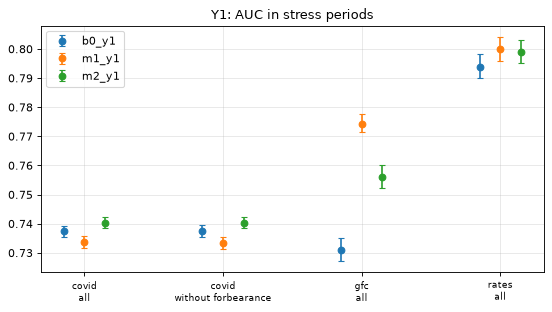

In [3]:
fig, axes = plt.subplots(1, len(TASKS), figsize=(7 * len(TASKS), 4), squeeze=False)
for ax, task in zip(axes[0], TASKS):
    s = stress[(stress["task"] == task)]
    labels = [f"{a}\n{b}" for a, b in s[["scenario", "variant"]].drop_duplicates().itertuples(index=False)]
    x = np.arange(len(labels))
    for k, m in enumerate(MAIN[task]):
        mm = s[s["model"] == m]
        ax.errorbar(x + (k - 1) * 0.15, mm["auc"], yerr=[mm["auc"] - mm["auc_lo"], mm["auc_hi"] - mm["auc"]], fmt="o", capsize=3, label=m)
    ax.set_xticks(x, labels, fontsize=8); ax.set_title(f"{task.upper()}: AUC in stress periods"); ax.legend()
plt.tight_layout(); plt.show()

**EN. How to read.** **The ranking holds under stress but is much weaker, and the PD level is far too low.** M1 AUC: test 0.838 → crisis 2007–2009 0.774, COVID 0.734, rising rates 0.800. **In the 2007–2009 crisis M1 is clearly stronger than the scorecard**: 0.774 [0.771; 0.778] vs B0 0.731 [0.727; 0.735] (+0.043, three times the test gain), M2 0.756: under pre-crisis underwriting the feature interactions the scorecard cannot see matter. **In COVID M1 is not better than the scorecard**: B0 0.737 [0.735; 0.739], M1 0.734 [0.732; 0.736], M2 0.740 [0.738; 0.742] — the intervals of B0 and M1 do not overlap, here the scorecard is slightly ahead; 2020–2021 delinquency was driven by a labour-market shock and payment pauses that the features do not see. Rising rates: the three models are close (0.794–0.800). Calibration: observed event rate vs mean PD of M1 — COVID 1.48 % vs 0.23 % (≈ 6×), crisis 2.64 % vs 1.00 % (≈ 2.6×), rates 0.29 % vs 0.21 % (≈ 1.4×); intercept +1.9 / +1.1 / +0.3, slope 0.57–0.72. The model does not know a crisis has begun; banks adjust provisions through IFRS 9 macro scenarios, while the monitoring list needs the ranking. In the crisis M1's list (PD ≥ 0.01) covers 21 % of rows and catches 58 % of events and 66 % of the EL. Forbearance rows at t are only 0.26 % of COVID rows; without them the metrics barely change (M1 0.733).

**RU. Как читать.** **Ранжирование в стрессе сохраняется, но заметно слабее, а уровень PD сильно занижен.** AUC M1: test 0,838 → кризис 2007–2009 гг. 0,774, COVID 0,734, рост ставок 0,800. **В кризисе 2007–2009 гг. M1 заметно сильнее скоринговой карты**: 0,774 [0,771; 0,778] против B0 0,731 [0,727; 0,735] (+0,043, втрое больше выигрыша на test), M2 0,756: при других (докризисных) правилах выдачи важны взаимодействия признаков, которых карта не видит. **В COVID M1 не лучше карты**: B0 0,737 [0,735; 0,739], M1 0,734 [0,732; 0,736], M2 0,740 [0,738; 0,742] — интервалы B0 и M1 не пересекаются, здесь карта немного впереди; просрочка 2020–2021 гг. вызвана шоком рынка труда и паузами в платежах, которых признаки не видят. Рост ставок: три модели близки (0,794–0,800). Калибровка: фактическая доля событий против средней PD M1 — COVID 1,48 % против 0,23 % (≈ 6 раз), кризис 2,64 % против 1,00 % (≈ 2,6 раза), ставки 0,29 % против 0,21 % (≈ 1,4 раза); intercept +1,9 / +1,1 / +0,3, slope 0,57–0,72. Модель не знает, что начался кризис; банк корректирует резервы через макро-сценарии МСФО 9, а списку мониторинга нужно ранжирование. В кризис список M1 (PD ≥ 0,01) — 21 % строк, ловит 58 % событий и 66 % EL. Строки в forbearance на дату t — лишь 0,26 % строк COVID; без них метрики почти не меняются (M1 0,733).

**EN.** One CatBoost with the main hyperparameters and number of trees, trained on CPU on vintages 2014–2017 (dates ≤ 2019-02, r = 0.2, weight ω × 1/r), evaluated on vintage 2018. For reference: the main M1 on the same 2018 rows (it was trained on earlier dates of older vintages). The calibration of both is checked by the calibration intercept and slope only (no recalibration on 2018).

**RU.** Одна модель CatBoost с основными гиперпараметрами и числом деревьев, обучена на CPU на поколениях 2014–2017 (даты ≤ 2019-02, r = 0,2, вес ω × 1/r), оценка — на поколении 2018. Для сравнения — основная M1 на тех же строках 2018 г. (она обучена на более ранних датах старых поколений). Калибровка обеих — только по calibration intercept и slope (без перекалибровки на 2018).

In [4]:
vint = []
for task in TASKS:
    # trained by scripts/fit_stress_models.py before the protocol was frozen (cached)
    model, enc, _ = registry.fit_single_catboost(f"vintage_{task}", lambda: load_vintage_train(task, FEATS, CATS),
                                                 FEATS, CATS, task, f"catboost_{task}_main")
    va = load_eval("vintage_validation", task, FEATS, CATS)
    zv = cb.logit(model, cb.pool(to_model_frame(va, FEATS, enc), cat_features=CATS))
    zm = registry.predict(f"m1_{task}", va)
    y = va[task].to_numpy()
    for n, z in (("vintage model", zv), ("main M1", zm)):
        p = 1 / (1 + np.exp(-z))
        s, i = calibration_slope_intercept(y, registry.calibrator(f"m1_{task}").predict(z) if n == "main M1" else p)
        vint.append({"task": task, "model": n, "rows": va.height, "events": int(y.sum()), "auc": auc(y, z), "ks": ks(y, z),
                     "cal_slope": s, "cal_intercept": i})
    pw = pairwise(y, {"vintage": zv, "main": zm}, va["loan_identifier"].to_numpy(), [("vintage", "main")], b=B, seed=SEED)
    vint.append({"task": task, "model": "Δ vintage − main", "auc": pw.loc[0, "delta_auc"], "delta_lo": pw.loc[0, "lo"],
                 "delta_hi": pw.loc[0, "hi"], "delong_p": pw.loc[0, "delong_p"]})
vintage = pd.DataFrame(vint)
vintage.to_csv(OUT / "vintage_split.csv", index=False)
vintage

,task,model,rows,events,auc,ks,cal_slope,cal_intercept,delta_lo,delta_hi,delong_p
0,y1,vintage model,"195,153.0000",632.0000,0.8249,0.5047,1.1397,-0.1214,NaN,NaN,NaN
1,y1,main M1,"195,153.0000",632.0000,0.8229,0.5117,0.9829,0.1460,NaN,NaN,NaN
2,y1,Δ vintage − main,NaN,NaN,0.0020,NaN,NaN,NaN,-0.0035,0.0078,0.5344


**EN. How to read.** The model trained on vintages 2014–2017 reaches AUC 0.825 on the 2018 vintage (t ≤ 2019-02; 195,153 rows, only 632 events) — the same as the main M1 on the same rows (0.823; Δ +0.002 [−0.003; +0.008], p = 0.53). The results do not depend on splitting by observation date or by vintage. The main M1 slightly underestimates the level for this young cohort (intercept +0.15, slope 0.98); the vintage model without calibration has intercept −0.12, slope 1.14.

**RU. Как читать.** Модель, обученная на поколениях 2014–2017, на поколении 2018 (t ≤ 2019-02; 195 153 строки, всего 632 события) даёт AUC 0,825 — столько же, сколько основная M1 на тех же строках (0,823; Δ +0,002 [−0,003; +0,008], p = 0,53). Результаты не зависят от того, разбивать ли по дате наблюдения или по поколению. Основная M1 немного занижает уровень для этой молодой когорты (intercept +0,15, slope 0,98); модель по поколениям без калибровки — intercept −0,12, slope 1,14.

**EN.** Two single CPU CatBoost models with the main hyperparameters on the full train (r = 0.2): the 18 selected features, and the same plus `unemployment_rel_us` and `unemployment_chg_12m_rel_us`. Same training procedure, so the difference reflects only the unemployment features. Evaluated on validation half A (where unemployment was rejected) and on COVID.

**RU.** Две одиночные модели CatBoost на CPU с основными гиперпараметрами на полном train (r = 0,2): 18 отобранных признаков и они же плюс `unemployment_rel_us` и `unemployment_chg_12m_rel_us`. Процедура обучения одинаковая, поэтому разница отражает только признаки безработицы. Оценка — на половине A validation (где безработица была отвергнута) и на COVID.

In [5]:
unemp_rows = []
for task in TASKS:
    # single CPU models trained by scripts/fit_stress_models.py before the protocol was frozen
    names = {"selected": f"unemp_{task}_{len(FEATS)}", "selected + unemployment": f"unemp_{task}_{len(FEATS) + 2}"}
    for sample in ("validation", "covid"):
        d = registry.score_by_month(sample, task, list(names.values()), FEATS + UNEMP, CATS,
                                    keep=["loan_identifier", "m", task, *(["half"] if sample == "validation" else [])],
                                    calibrate=False)
        if sample == "validation":
            d = d.filter(pl.col("half") == "A")
        zs = {tag: d[f"z_{n}"].to_numpy() for tag, n in names.items()}
        pw = pairwise(d[task].to_numpy(), zs, loan_codes(d), [("selected + unemployment", "selected")], b=B, seed=SEED)
        unemp_rows.append({"task": task, "sample": sample, **{f"auc {k}": auc(d[task].to_numpy(), z) for k, z in zs.items()},
                           **pw.iloc[0][["delta_auc", "lo", "hi", "delong_p"]].to_dict()})
        del d, zs; gc.collect()
unemployment = pd.DataFrame(unemp_rows)
unemployment.to_csv(OUT / "covid_unemployment.csv", index=False)
unemployment

,task,sample,auc selected,auc selected + unemployment,delta_auc,lo,hi,delong_p
0,y1,validation,0.8610,0.8608,-0.0003,-0.0024,0.0018,0.2372
1,y1,covid,0.7340,0.7327,-0.0014,-0.0018,-0.0009,0.0124


**EN. How to read.** On validation (2016–2017) the two unemployment features add nothing (ΔAUC −0.0003 [−0.0024; +0.0018], p = 0.24) — consistent with their exclusion in stage 2. **In COVID they do not help either**: ΔAUC −0.0014 [−0.0018; −0.0009], DeLong p = 0.012 — the model with unemployment is slightly worse. The idea that unemployment matters exactly when the shock comes through employment is not supported for Y1. A likely reason: the unemployment of the area at t lags the 2020 shock and shifts the overall level of risk more than the order of loans within it. The exclusion of unemployment from the selected set stands.

**RU. Как читать.** На validation (2016–2017 гг.) два признака безработицы ничего не добавляют (ΔAUC −0,0003 [−0,0024; +0,0018], p = 0,24) — согласуется с их исключением на этапе 2. **В COVID они тоже не помогают**: ΔAUC −0,0014 [−0,0018; −0,0009], p DeLong = 0,012 — модель с безработицей немного хуже. Предположение, что безработица важна именно при шоке занятости, для Y1 не подтверждается. Вероятная причина: безработица в районе на дату t запаздывает за шоком 2020 г. и сдвигает общий уровень риска сильнее, чем порядок кредитов внутри него. Исключение безработицы из отобранного набора остаётся в силе.

### 4. Sign of `occupancy_status` / Знак `occupancy_status`

**EN.** Mean SHAP contribution of `occupancy_status` (logit scale, M1 fold average) for each occupancy category, within FICO bands, on a sample of 60 000 rows per period (validation half A as the reference, then the stress periods). Positive = the category raises the predicted risk. Next to it — the observed event rate by category. Descriptive.

**RU.** Средний вклад SHAP признака `occupancy_status` (в логитах, среднее по фолдовым моделям M1) для каждой категории проживания внутри групп FICO, на выборке 60 000 строк на период (эталон — половина A validation, затем стресс-периоды). Положительный — категория повышает прогнозируемый риск. Рядом — наблюдаемая доля событий по категориям. Описательно.

In [6]:
occ_rows = []
meta = registry.meta("m1_y1")
enc = pickle.loads((MODELS_DIR / "m1_y1" / "encoder.pkl").read_bytes())
folds = []
for k in range(cb.K_FOLDS):
    mk = CatBoostClassifier(); mk.load_model(str(MODELS_DIR / "m1_y1" / f"fold_{k}.cbm")); folds.append(mk)
j = meta["features"].index("occupancy_status")
for sample in ("validation", *SCENARIOS):
    # a random subset of loans (uniform hash draw u_holdout in [0.3, 0.3 + f)) instead of loading the whole sample
    n = scan_panel().filter(split_filter(sample) & pl.col("pop_y1") & pl.col("y1").is_not_null()).select(pl.len()).collect().item()
    f = min(0.7, 2 * 60_000 / n)
    d = load_eval(sample, "y1", FEATS, CATS, where=pl.col("u_holdout").is_between(0.3, 0.3 + f, closed="left"))
    if sample == "validation":
        d = d.filter(pl.col("half") == "A")
    d = d.sample(n=min(60_000, d.height), seed=SEED)
    pool = cb.pool(to_model_frame(d, FEATS, enc), cat_features=CATS)
    sv = np.mean([m.get_feature_importance(pool, type="ShapValues")[:, j] for m in folds], axis=0)
    fico = pd.cut(d["borrower_credit_score_at_origination"].to_numpy(), [0, 680, 740, 900], right=False,
                  labels=["<680", "680-739", ">=740"])
    t = pd.DataFrame({"occupancy": d["occupancy_status"].to_numpy(), "fico": fico, "shap": sv, "y1": d["y1"].to_numpy()})
    g = t.groupby(["fico", "occupancy"], observed=True).agg(rows=("shap", "size"), mean_shap=("shap", "mean"), y1_rate=("y1", "mean"))
    occ_rows.append(g.assign(sample=sample).reset_index())
    del d, pool; gc.collect()
occupancy = pd.concat(occ_rows)
occupancy.to_csv(OUT / "occupancy_shap.csv", index=False)
occupancy.pivot_table(index=["fico", "occupancy"], columns="sample", values=["mean_shap", "y1_rate"])

mean_shap                            y1_rate                         
sample                covid     gfc   rates validation   covid    gfc  rates validation
fico    occupancy                                                                      
<680    I           -0.2240 -0.2132 -0.2100    -0.2283  0.0048 0.0443 0.0000     0.0100
        P            0.0199  0.0191  0.0189     0.0201  0.0452 0.0505 0.0169     0.0102
        S            0.0050  0.1236 -0.0071    -0.0014  0.0530 0.0334 0.0000     0.0290
680-739 I           -0.2701 -0.2552 -0.2455    -0.2715  0.0343 0.0235 0.0035     0.0021
        P            0.0221  0.0291  0.0214     0.0218  0.0231 0.0358 0.0051     0.0040
        S           -0.0523  0.0695 -0.0492    -0.0695  0.0318 0.0234 0.0026     0.0025
>=740   I           -0.2727 -0.2212 -0.2556    -0.2833  0.0120 0.0190 0.0011     0.0013
        P            0.0286  0.0290  0.0273     0.0293  0.0091 0.0115 0.0017     0.0003
        S           -0.1291 -0.0134 -0.1231    -0.1325  0.0042 0.0070 0.0005     0.0000

**EN. How to read.** The model's SHAP contribution of occupancy hardly changes between periods: investor I −0.21 … −0.28, owner-occupied P +0.02 … +0.03 in logits; second home S −0.01 … −0.13, except the crisis sample, where S in the bands below 740 is positive (+0.07 … +0.12) through interactions with other features. The fixed model keeps treating investors as safer. Observed Y1 rates (157–3,942 investor rows per band and period, so descriptive): in the 2007–2009 crisis investors with FICO ≥ 740 were riskier than owner-occupiers (1.9 % vs 1.1 %), in the lower bands they were not (2.4 % vs 3.6 %, 4.4 % vs 5.0 %); in COVID investors were riskier in both bands from 680 up (1.2 % vs 0.9 %, 3.4 % vs 2.3 %). So under stress the model under-ranks prime investors; this is the anticipated regime dependence, a limitation to monitor, not a reason to impose a sign.

**RU. Как читать.** Вклад SHAP признака `occupancy_status` почти не меняется между периодами: инвестор I −0,21 … −0,28, живёт в доме P +0,02 … +0,03 в логитах; второе жильё S −0,01 … −0,13, кроме кризисной выборки, где S в группах ниже 740 положителен (+0,07 … +0,12) из-за взаимодействий с другими признаками. Зафиксированная модель продолжает считать инвесторов безопаснее. Наблюдаемые доли Y1 (157–3 942 строки инвесторов на группу и период — описательно): в кризис 2007–2009 гг. инвесторы с FICO ≥ 740 были рискованнее живущих в доме (1,9 % против 1,1 %), в нижних группах — нет (2,4 % против 3,6 %, 4,4 % против 5,0 %); в COVID инвесторы были рискованнее в обеих группах от 680 (1,2 % против 0,9 %, 3,4 % против 2,3 %). Значит, в стрессе модель недооценивает prime-инвесторов; это ожидавшаяся зависимость от режима — ограничение для мониторинга, а не повод навязывать знак.

**EN. Summary.** Stress tests (evaluation only): the ranking survives every period with a lower AUC (M1: crisis 0.774, COVID 0.734, rates 0.800 vs 0.838 on test), while the PD level is 1.4–6 times too low — the monitoring list works, provisions need macro scenarios. In the 2007–2009 crisis CatBoost beats the scorecard by +0.043 AUC; in COVID it does not (the scorecard is slightly ahead, the MLP is best). The vintage split gives the same quality as the main split. Unemployment does not help, in COVID either. The model keeps treating investors as safer, which was not true for prime investors in 2007–2009 and in COVID. M1 logits for the stress periods are saved for stage 4.

**RU. Итог.** Стресс-тесты (только оценка): ранжирование сохраняется во всех периодах при более низком AUC (M1: кризис 0,774, COVID 0,734, ставки 0,800 против 0,838 на test), а уровень PD занижен в 1,4–6 раз — список мониторинга работает, резервам нужны макро-сценарии. В кризис 2007–2009 гг. CatBoost обходит скоринговую карту на +0,043 AUC; в COVID — нет (карта немного впереди, лучше всех MLP). Разбиение по поколениям даёт то же качество, что основное разбиение. Безработица не помогает, в том числе в COVID. Модель продолжает считать инвесторов безопаснее, что для prime-инвесторов в 2007–2009 гг. и в COVID было неверно. Логиты M1 на стресс-периодах сохранены для этапа 4.